# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 02: Iris Segmentation

### Objective

This notebook performs **raw iris segmentation** after Notebook 01 dataset exploration.

The notebook must:

1. Read the image-level metadata produced by Notebook 01.
2. Load raw eye images.
3. Detect the **pupil boundary**.
4. Detect the **limbus / outer iris boundary**.
5. Remove or mask **eyelid occlusion**.
6. Mask **eyelashes**.
7. Mask **specular reflections**.
8. Build a final binary **usable-iris mask**.
9. Save segmented iris images without altering the raw dataset.
10. Save segmentation metadata for Notebook 03 and later quality analysis.
11. Produce visual quality-control examples and failure statistics.

### Important boundary of this notebook

This notebook performs **segmentation only**.

It does **not** perform:

- rubber-sheet normalization,
- CLAHE,
- histogram equalization,
- gamma correction,
- denoising/sharpening as a final preprocessing stage,
- quality-score filtering,
- few-shot split creation,
- model training.

Those are handled by later notebooks.

### Method choice

The project proposal listed Hough Transform, DeepLabV3+, YOLO segmentation, and U-Net as possible segmentation approaches. Because Notebook 01 does not create pixel-level segmentation labels, this notebook uses a **label-free classical segmentation pipeline** as the reproducible starting implementation:

- Hough-circle based pupil detection,
- Hough-circle / radial-gradient based limbus detection,
- edge/line based eyelid masking,
- morphology-based eyelash masking,
- intensity/morphology-based reflection masking.

A supervised U-Net/DeepLabV3+/YOLO implementation should only be introduced when suitable segmentation annotations are available. An untrained segmentation network would not be a valid replacement.

## 1. Research rationale

Iris segmentation is the stage that isolates the iris from the rest of the eye image before normalization.

The inner boundary is the pupil boundary and the outer boundary is the limbus. Daugman's classical iris-recognition work models these boundaries as circular contour-search problems, while OpenCV's Hough Circle Transform provides a practical gradient-based circle detector.

The segmentation result used by later notebooks is therefore:

```text
Raw eye image
      |
      +----> pupil boundary
      |
      +----> limbus boundary
      |
      +----> eyelid mask
      |
      +----> eyelash mask
      |
      +----> reflection mask
      |
      v
Final iris mask
      |
      v
Segmented iris image
```

The final iris mask excludes the pupil and detected occlusions; the circular limbus region defines the outer iris extent.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

from pathlib import Path
import json
import math
import random
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from IPython.display import display

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

RAW_DATA_DIR = PROJECT_ROOT / "datasets" / "raw"
RESULTS_DIR = PROJECT_ROOT / "results" / "iris_segmentation"

NOTEBOOK01_RESULTS_DIR = PROJECT_ROOT / "results" / "dataset_exploration"
METADATA_PATH = NOTEBOOK01_RESULTS_DIR / "image_metadata.csv"

SEGMENTED_DIR = RESULTS_DIR / "segmented"
MASKS_DIR = RESULTS_DIR / "masks"
PREVIEW_DIR = RESULTS_DIR / "previews"

SEGMENTED_DIR.mkdir(parents=True, exist_ok=True)
MASKS_DIR.mkdir(parents=True, exist_ok=True)
PREVIEW_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Notebook 01 metadata:", METADATA_PATH)
print("Notebook 02 results:", RESULTS_DIR)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 01 metadata: E:\Research\LargeScale_Synthetic_Iris_Generation\results\dataset_exploration\image_metadata.csv
Notebook 02 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_segmentation


In [3]:
# ============================================================
# 4. Load Notebook 01 metadata
# ============================================================

if not METADATA_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 01 metadata was not found at: {METADATA_PATH}\n"
        "Run 01_Dataset_Exploration.ipynb first."
    )

metadata = pd.read_csv(METADATA_PATH)

required_columns = {
    "dataset",
    "identity",
    "eye",
    "filename",
    "full_path",
}

missing = required_columns.difference(metadata.columns)

if missing:
    raise ValueError(
        f"Notebook 01 metadata is missing required columns: {sorted(missing)}"
    )

print("Metadata shape:", metadata.shape)
display(metadata.head())

Metadata shape: (22180, 12)


,dataset,filename,relative_path,full_path,extension,width,height,mode,channels,file_size_bytes,identity,eye
0,CASIA-Iris-Thousand,S5000L00.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,E:\Research\LargeScale_Synthetic_Iris_Generati...,.jpg,640,480,L,1,23338,0,L
1,CASIA-Iris-Thousand,S5000L01.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,E:\Research\LargeScale_Synthetic_Iris_Generati...,.jpg,640,480,L,1,23295,0,L
2,CASIA-Iris-Thousand,S5000L02.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,E:\Research\LargeScale_Synthetic_Iris_Generati...,.jpg,640,480,L,1,24058,0,L
3,CASIA-Iris-Thousand,S5000L03.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,E:\Research\LargeScale_Synthetic_Iris_Generati...,.jpg,640,480,L,1,24352,0,L
4,CASIA-Iris-Thousand,S5000L04.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,E:\Research\LargeScale_Synthetic_Iris_Generati...,.jpg,640,480,L,1,26020,0,L


## 5. Configuration

The default mode processes all images.

For an initial test, set `MAX_IMAGES_PER_DATASET` to a small integer such as `20`. After verifying the previews, set it to `None` and run the complete dataset.

The detector thresholds are expressed mainly as fractions of image dimensions/radii so that the code is less dependent on one fixed image resolution.

In [4]:
# ============================================================
# 5. Configuration
# ============================================================

MAX_IMAGES_PER_DATASET = None   # e.g. 20 for an initial test; None = all
SAVE_PREVIEWS = True
PREVIEW_COUNT_PER_DATASET = 12

# Internal processing resolution.
# Detection is performed on a resized copy and mapped back to original size.
PROCESSING_MAX_DIM = 800

# Pupil Hough search range as a fraction of the shorter image dimension.
PUPIL_MIN_RADIUS_FRAC = 0.035
PUPIL_MAX_RADIUS_FRAC = 0.20

# Limbus Hough search range.
LIMBUS_MIN_RADIUS_FRAC = 0.22
LIMBUS_MAX_RADIUS_FRAC = 0.50

# Plausible limbus-to-pupil radius ratio.
MIN_LIMBUS_PUPIL_RATIO = 1.6
MAX_LIMBUS_PUPIL_RATIO = 5.0

# Circle detector parameters.
HOUGH_DP = 1.2
PUPIL_PARAM1 = 90
PUPIL_PARAM2 = 20
LIMBUS_PARAM1 = 100
LIMBUS_PARAM2 = 25

# Maximum normalized center displacement allowed for limbus candidate ranking.
MAX_CENTER_OFFSET_FRAC = 0.25

print("Configuration loaded.")

Configuration loaded.


In [5]:
# ============================================================
# 6. Utility functions
# ============================================================

def safe_read_gray(path):
    """Read an image as uint8 grayscale."""
    path = Path(path)
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise ValueError(f"Unable to read image: {path}")

    if image.dtype != np.uint8:
        image = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    return image


def resize_for_processing(gray, max_dim=800):
    """Resize only the working copy; never overwrite the raw image."""
    h, w = gray.shape

    scale = min(1.0, max_dim / max(h, w))

    if scale == 1.0:
        return gray.copy(), 1.0

    resized = cv2.resize(
        gray,
        None,
        fx=scale,
        fy=scale,
        interpolation=cv2.INTER_AREA,
    )

    return resized, scale


def circle_mask(shape, cx, cy, radius, value=255):
    """Create a filled circular mask."""
    h, w = shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)

    if cx is None or cy is None or radius is None:
        return mask

    cv2.circle(
        mask,
        (int(round(cx)), int(round(cy))),
        max(1, int(round(radius))),
        int(value),
        thickness=-1,
    )

    return mask


def sample_circle_points(cx, cy, radius, n=720):
    """Return integer pixel coordinates sampled around a circle."""
    theta = np.linspace(0, 2 * np.pi, n, endpoint=False)

    x = np.rint(cx + radius * np.cos(theta)).astype(int)
    y = np.rint(cy + radius * np.sin(theta)).astype(int)

    return x, y


def valid_points(x, y, shape):
    """Keep only points inside an image."""
    h, w = shape[:2]

    valid = (
        (x >= 0) & (x < w) &
        (y >= 0) & (y < h)
    )

    return x[valid], y[valid]


def circle_gradient_score(gradient_magnitude, cx, cy, radius):
    """Mean gradient magnitude sampled along a circle."""
    x, y = sample_circle_points(cx, cy, radius)
    x, y = valid_points(x, y, gradient_magnitude.shape)

    if len(x) < 20:
        return 0.0

    return float(np.mean(gradient_magnitude[y, x]))


def mean_inside_circle(gray, cx, cy, radius):
    """Mean intensity within a circle."""
    mask = circle_mask(gray.shape, cx, cy, radius, 255)

    values = gray[mask > 0]

    if values.size == 0:
        return np.nan

    return float(values.mean())


def mean_ring(gray, cx, cy, inner_radius, outer_radius):
    """Mean intensity inside an annular ring."""
    outer = circle_mask(gray.shape, cx, cy, outer_radius, 255)
    inner = circle_mask(gray.shape, cx, cy, inner_radius, 255)

    ring = cv2.subtract(outer, inner)
    values = gray[ring > 0]

    if values.size == 0:
        return np.nan

    return float(values.mean())


def connected_components_mask(binary):
    """Return connected-component statistics for a binary mask."""
    n_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        binary,
        connectivity=8,
    )

    records = []

    for label in range(1, n_labels):
        x, y, w, h, area = stats[label]

        records.append({
            "label": label,
            "x": int(x),
            "y": int(y),
            "width": int(w),
            "height": int(h),
            "area": int(area),
            "centroid_x": float(centroids[label][0]),
            "centroid_y": float(centroids[label][1]),
        })

    return pd.DataFrame(records)

## 7. Pupil detection

The pupil is the inner boundary of the iris.

A two-stage detector is used:

1. Hough circles on a smoothed grayscale image.
2. A threshold/connected-component fallback if Hough does not produce a plausible pupil.

Candidate selection uses:
- darkness of the candidate circle,
- contrast with its surrounding annulus,
- distance from the image center.

This is intentionally conservative: a candidate is accepted only when its geometry is plausible.

In [6]:
# ============================================================
# 7. Pupil detection
# ============================================================

def detect_pupil(gray):
    """Detect the pupil using Hough circles with a dark-region fallback."""
    h, w = gray.shape
    min_dim = min(h, w)

    blurred = cv2.GaussianBlur(gray, (9, 9), 2)

    min_r = max(3, int(PUPIL_MIN_RADIUS_FRAC * min_dim))
    max_r = max(min_r + 2, int(PUPIL_MAX_RADIUS_FRAC * min_dim))

    circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=HOUGH_DP,
        minDist=max(20, int(0.15 * min_dim)),
        param1=PUPIL_PARAM1,
        param2=PUPIL_PARAM2,
        minRadius=min_r,
        maxRadius=max_r,
    )

    candidates = []

    if circles is not None:
        circles = np.round(circles[0]).astype(int)

        image_cx = w / 2.0
        image_cy = h / 2.0

        for x, y, r in circles:
            if r <= 0:
                continue

            if not (0 <= x < w and 0 <= y < h):
                continue

            inside_mean = mean_inside_circle(gray, x, y, r)
            outside_mean = mean_ring(
                gray,
                x,
                y,
                max(1, int(1.15 * r)),
                max(2, int(1.70 * r)),
            )

            if np.isnan(inside_mean) or np.isnan(outside_mean):
                continue

            darkness_score = max(0.0, outside_mean - inside_mean)

            center_distance = math.sqrt(
                ((x - image_cx) / w) ** 2 +
                ((y - image_cy) / h) ** 2
            )

            center_score = max(0.0, 1.0 - center_distance / 0.5)

            # Higher is better.
            score = (
                0.75 * darkness_score +
                25.0 * center_score
            )

            candidates.append({
                "cx": int(x),
                "cy": int(y),
                "radius": int(r),
                "score": float(score),
                "method": "hough",
                "darkness_score": float(darkness_score),
                "center_score": float(center_score),
            })

    if candidates:
        candidates.sort(key=lambda d: d["score"], reverse=True)
        best = candidates[0]

        # Reject very weak candidates.
        if best["darkness_score"] >= 3.0:
            return best

    # --------------------------------------------------------
    # Fallback: dark connected-component detection
    # --------------------------------------------------------

    # Focus on the central 80% of the image.
    roi_mask = np.zeros_like(gray, dtype=np.uint8)

    x0 = int(0.10 * w)
    x1 = int(0.90 * w)
    y0 = int(0.10 * h)
    y1 = int(0.90 * h)

    roi_mask[y0:y1, x0:x1] = 255

    central_values = gray[roi_mask > 0]
    threshold = float(np.percentile(central_values, 12))

    dark = np.where(gray <= threshold, 255, 0).astype(np.uint8)
    dark = cv2.bitwise_and(dark, roi_mask)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    dark = cv2.morphologyEx(dark, cv2.MORPH_CLOSE, kernel, iterations=2)

    components = connected_components_mask(dark)

    if not components.empty:
        image_cx = w / 2.0
        image_cy = h / 2.0

        fallback_candidates = []

        for _, row in components.iterrows():
            area = row["area"]

            if area < 0.002 * h * w:
                continue

            if area > 0.12 * h * w:
                continue

            cx = row["centroid_x"]
            cy = row["centroid_y"]

            radius = math.sqrt(area / math.pi)

            if not (min_r * 0.6 <= radius <= max_r * 1.5):
                continue

            center_distance = math.sqrt(
                ((cx - image_cx) / w) ** 2 +
                ((cy - image_cy) / h) ** 2
            )

            center_score = max(0.0, 1.0 - center_distance / 0.5)

            fallback_candidates.append({
                "cx": int(round(cx)),
                "cy": int(round(cy)),
                "radius": int(round(radius)),
                "score": float(center_score),
                "method": "dark_component",
                "darkness_score": np.nan,
                "center_score": float(center_score),
            })

        if fallback_candidates:
            fallback_candidates.sort(
                key=lambda d: d["score"],
                reverse=True,
            )
            return fallback_candidates[0]

    return None

## 8. Limbus detection

The limbus is the outer iris boundary.

The detector first searches for Hough-circle candidates in an iris-sized radius range. Candidate circles are ranked by:

- plausible radius relative to the detected pupil,
- proximity to the pupil center,
- radial edge strength along the circle.

If Hough detection fails, a radial-gradient fallback searches radii around the pupil center.

This is a practical classical implementation, not a claim that Hough detection is perfect for every image. Detection failures are explicitly recorded for later review.

In [7]:
# ============================================================
# 8. Limbus detection
# ============================================================

def detect_limbus(gray, pupil):
    """Detect the outer iris/limbus boundary."""
    if pupil is None:
        return None

    h, w = gray.shape
    min_dim = min(h, w)

    px = float(pupil["cx"])
    py = float(pupil["cy"])
    pr = float(pupil["radius"])

    blurred = cv2.GaussianBlur(gray, (7, 7), 1.5)

    gx = cv2.Sobel(blurred, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(blurred, cv2.CV_32F, 0, 1, ksize=3)
    gradient_mag = cv2.magnitude(gx, gy)

    min_r = max(
        int(LIMBUS_MIN_RADIUS_FRAC * min_dim),
        int(MIN_LIMBUS_PUPIL_RATIO * pr),
    )

    max_r = max(
        min_r + 5,
        int(LIMBUS_MAX_RADIUS_FRAC * min_dim),
    )

    circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=HOUGH_DP,
        minDist=max(20, int(0.30 * min_dim)),
        param1=LIMBUS_PARAM1,
        param2=LIMBUS_PARAM2,
        minRadius=min_r,
        maxRadius=max_r,
    )

    candidates = []

    if circles is not None:
        circles = np.round(circles[0]).astype(int)

        for x, y, r in circles:
            if r <= 0:
                continue

            ratio = r / max(pr, 1.0)

            if not (
                MIN_LIMBUS_PUPIL_RATIO <= ratio <= MAX_LIMBUS_PUPIL_RATIO
            ):
                continue

            center_distance = math.sqrt(
                (x - px) ** 2 + (y - py) ** 2
            )

            center_offset_frac = center_distance / max(r, 1.0)

            if center_offset_frac > MAX_CENTER_OFFSET_FRAC:
                continue

            edge_score = circle_gradient_score(
                gradient_mag,
                x,
                y,
                r,
            )

            ratio_mid = (
                MIN_LIMBUS_PUPIL_RATIO +
                MAX_LIMBUS_PUPIL_RATIO
            ) / 2.0

            ratio_score = max(
                0.0,
                1.0 - abs(ratio - ratio_mid) / ratio_mid
            )

            center_score = max(
                0.0,
                1.0 - center_offset_frac / MAX_CENTER_OFFSET_FRAC
            )

            score = (
                0.65 * edge_score +
                30.0 * center_score +
                20.0 * ratio_score
            )

            candidates.append({
                "cx": int(x),
                "cy": int(y),
                "radius": int(r),
                "score": float(score),
                "method": "hough",
                "edge_score": float(edge_score),
                "center_score": float(center_score),
                "radius_ratio": float(ratio),
            })

    if candidates:
        candidates.sort(key=lambda d: d["score"], reverse=True)
        return candidates[0]

    # --------------------------------------------------------
    # Fallback: radial gradient search around pupil center.
    # --------------------------------------------------------

    search_min = max(
        int(MIN_LIMBUS_PUPIL_RATIO * pr),
        int(0.20 * min_dim),
    )

    search_max = max(
        search_min + 5,
        int(0.52 * min_dim),
    )

    radii = np.linspace(search_min, search_max, 90)

    radius_scores = []

    for r in radii:
        score = circle_gradient_score(
            gradient_mag,
            px,
            py,
            float(r),
        )
        radius_scores.append(score)

    if not radius_scores:
        return None

    best_idx = int(np.argmax(radius_scores))
    best_radius = float(radii[best_idx])
    best_score = float(radius_scores[best_idx])

    if best_score <= 0:
        return None

    return {
        "cx": int(round(px)),
        "cy": int(round(py)),
        "radius": int(round(best_radius)),
        "score": best_score,
        "method": "radial_gradient",
        "edge_score": best_score,
        "center_score": 1.0,
        "radius_ratio": best_radius / max(pr, 1.0),
    }

## 9. Eyelid masking

Eyelids can cover the upper and lower parts of the iris.

This implementation uses:

1. Canny edge detection.
2. Probabilistic Hough lines.
3. Selection of long, approximately horizontal edge segments in the upper/lower iris zones.
4. Line thickening and morphological joining.

The resulting mask is deliberately treated as an **occlusion mask**, not as a claim that the eyelid has been anatomically segmented perfectly.

In [8]:
# ============================================================
# 9. Eyelid masking
# ============================================================

def detect_eyelid_mask(gray, iris_mask, pupil, limbus):
    """Create an approximate upper/lower eyelid occlusion mask."""

    mask = np.zeros_like(gray, dtype=np.uint8)

    if limbus is None:
        return mask

    cx = limbus["cx"]
    cy = limbus["cy"]
    r = limbus["radius"]

    edges = cv2.Canny(
        cv2.GaussianBlur(gray, (5, 5), 1.2),
        threshold1=40,
        threshold2=100,
    )

    edges = cv2.bitwise_and(edges, iris_mask)

    lines = cv2.HoughLinesP(
        edges,
        rho=1,
        theta=np.pi / 180,
        threshold=max(20, int(0.08 * r)),
        minLineLength=max(20, int(0.25 * r)),
        maxLineGap=max(8, int(0.08 * r)),
    )

    line_mask = np.zeros_like(gray, dtype=np.uint8)

    if lines is not None:

        # Normalize OpenCV HoughLinesP output to shape (N, 4)
        lines = np.asarray(lines).reshape(-1, 4)

        for line in lines:

            x1, y1, x2, y2 = map(int, line)

            dx = x2 - x1
            dy = y2 - y1

            length = math.hypot(dx, dy)

            if length < 0.25 * r:
                continue

            angle = abs(
                math.degrees(
                    math.atan2(dy, dx)
                )
            )

            angle = min(angle, 180.0 - angle)

            # Eyelid edges are commonly close to horizontal.
            if angle > 28:
                continue

            mid_y = (y1 + y2) / 2.0

            vertical_position = (
                (mid_y - cy) / max(r, 1)
            )

            # Keep only upper and lower eyelid regions.
            if not (
                -1.0 <= vertical_position <= -0.05
                or
                0.05 <= vertical_position <= 1.0
            ):
                continue

            # Extend the detected line slightly.
            extension = 0.25

            ex = dx / max(length, 1.0)
            ey = dy / max(length, 1.0)

            nx1 = int(
                round(
                    x1 - extension * length * ex
                )
            )

            ny1 = int(
                round(
                    y1 - extension * length * ey
                )
            )

            nx2 = int(
                round(
                    x2 + extension * length * ex
                )
            )

            ny2 = int(
                round(
                    y2 + extension * length * ey
                )
            )

            thickness = max(
                4,
                int(0.035 * r)
            )

            cv2.line(
                line_mask,
                (nx1, ny1),
                (nx2, ny2),
                255,
                thickness=thickness,
            )

    # Connect fragmented eyelid detections.
    kernel_size = max(
        3,
        int(0.02 * r)
    )

    # Morphological kernel dimensions should preferably be odd.
    if kernel_size % 2 == 0:
        kernel_size += 1

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (kernel_size, kernel_size),
    )

    line_mask = cv2.morphologyEx(
        line_mask,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=1,
    )

    # Keep only pixels inside the iris.
    mask = cv2.bitwise_and(
        line_mask,
        iris_mask,
    )

    # Never mask the pupil through this stage.
    if pupil is not None:

        pupil_mask = circle_mask(
            gray.shape,
            pupil["cx"],
            pupil["cy"],
            pupil["radius"] * 1.05,
            255,
        )

        mask[pupil_mask > 0] = 0

    return mask

## 10. Eyelash masking

Eyelashes appear as dark, thin, elongated structures.

A black-hat morphological transform is useful for detecting dark structures against a lighter local background. To avoid destroying large portions of the iris texture, detection is restricted mainly to the upper and lower iris zones and the pupil is excluded.

In [9]:
# ============================================================
# 10. Eyelash masking
# ============================================================

def detect_eyelash_mask(gray, iris_mask, pupil, limbus):
    """Mask dark elongated eyelash-like structures."""
    mask = np.zeros_like(gray, dtype=np.uint8)

    if limbus is None:
        return mask

    r = float(limbus["radius"])
    cy = float(limbus["cy"])

    # Two orientations because eyelashes may be angled.
    k_h = max(7, int(0.10 * r) | 1)
    k_v = max(5, int(0.05 * r) | 1)

    horizontal_kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT,
        (k_h, 3),
    )

    vertical_kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT,
        (3, k_v),
    )

    blackhat_h = cv2.morphologyEx(
        gray,
        cv2.MORPH_BLACKHAT,
        horizontal_kernel,
    )

    blackhat_v = cv2.morphologyEx(
        gray,
        cv2.MORPH_BLACKHAT,
        vertical_kernel,
    )

    blackhat = cv2.max(blackhat_h, blackhat_v)

    # Consider mostly upper/lower iris regions.
    h, w = gray.shape
    yy = np.arange(h)[:, None]

    zone_mask = np.zeros((h, w), dtype=np.uint8)

    upper = yy < (cy - 0.02 * r)
    lower = yy > (cy + 0.02 * r)

    zone_mask[np.broadcast_to(upper, (h, w))] = 255
    zone_mask[np.broadcast_to(lower, (h, w))] = 255

    candidate_region = cv2.bitwise_and(
        iris_mask,
        zone_mask,
    )

    # Adaptive threshold from candidate region.
    values = blackhat[candidate_region > 0]

    if values.size == 0:
        return mask

    threshold = max(
        18.0,
        float(np.percentile(values, 97.5)),
    )

    binary = np.where(
        blackhat >= threshold,
        255,
        0,
    ).astype(np.uint8)

    binary = cv2.bitwise_and(
        binary,
        candidate_region,
    )

    # Remove very tiny components and excessively large regions.
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        binary,
        connectivity=8,
    )

    cleaned = np.zeros_like(binary)

    max_area = 0.03 * gray.shape[0] * gray.shape[1]

    for label in range(1, num_labels):
        x, y, cw, ch, area = stats[label]

        if 4 <= area <= max_area:
            cleaned[labels == label] = 255

    # Slight dilation makes the occlusion mask safer.
    dilate_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (3, 3),
    )

    cleaned = cv2.dilate(
        cleaned,
        dilate_kernel,
        iterations=1,
    )

    if pupil is not None:
        pupil_mask = circle_mask(
            gray.shape,
            pupil["cx"],
            pupil["cy"],
            pupil["radius"] * 1.05,
            255,
        )
        cleaned[pupil_mask > 0] = 0

    return cleaned

## 11. Reflection masking

Specular reflections are very bright, compact regions.

The procedure is:

- compute a high-percentile intensity threshold inside the iris,
- detect very bright connected components,
- remove tiny noise and unrealistically large bright regions,
- dilate slightly to cover the reflection halo.

The pixels are **masked**, not overwritten in the raw data.

In [10]:
# ============================================================
# 11. Reflection masking
# ============================================================

def detect_reflection_mask(gray, iris_mask, pupil, limbus):
    """Detect bright specular reflection regions inside the iris."""
    mask = np.zeros_like(gray, dtype=np.uint8)

    if limbus is None:
        return mask

    values = gray[iris_mask > 0]

    if values.size == 0:
        return mask

    percentile_threshold = float(np.percentile(values, 99.5))
    threshold = max(240.0, percentile_threshold)

    bright = np.where(gray >= threshold, 255, 0).astype(np.uint8)
    bright = cv2.bitwise_and(bright, iris_mask)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        bright,
        connectivity=8,
    )

    cleaned = np.zeros_like(bright)

    max_area = 0.02 * gray.shape[0] * gray.shape[1]

    for label in range(1, num_labels):
        x, y, w, h, area = stats[label]

        if 2 <= area <= max_area:
            cleaned[labels == label] = 255

    # Expand a little around the saturated highlight.
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (3, 3),
    )

    cleaned = cv2.dilate(
        cleaned,
        kernel,
        iterations=1,
    )

    if pupil is not None:
        pupil_mask = circle_mask(
            gray.shape,
            pupil["cx"],
            pupil["cy"],
            pupil["radius"] * 1.05,
            255,
        )
        cleaned[pupil_mask > 0] = 0

    return cleaned

## 12. Complete segmentation function

This function runs the entire Notebook 02 pipeline for one image.

Final mask logic:

```text
limbus disk
    MINUS pupil disk
    MINUS eyelid mask
    MINUS eyelash mask
    MINUS reflection mask
    =
final usable iris mask
```

The segmented image is the original grayscale image multiplied by the final mask.

In [11]:
# ============================================================
# 12. Complete segmentation function
# ============================================================

def scale_circle(circle, inverse_scale):
    """Map a detected circle from processing resolution to original resolution."""
    if circle is None:
        return None

    return {
        key: (
            value * inverse_scale
            if key in {"cx", "cy", "radius"}
            else value
        )
        for key, value in circle.items()
    }


def segment_iris_image(gray_original):
    """Run the complete iris segmentation pipeline."""

    gray_proc, scale = resize_for_processing(
        gray_original,
        PROCESSING_MAX_DIM,
    )

    # 1. Detect pupil.
    pupil_proc = detect_pupil(gray_proc)

    # 2. Detect limbus.
    limbus_proc = detect_limbus(
        gray_proc,
        pupil_proc,
    )

    # If either boundary fails, return a structured failure result.
    if pupil_proc is None:
        return {
            "success": False,
            "reason": "pupil_detection_failed",
            "pupil": None,
            "limbus": None,
            "iris_mask": np.zeros_like(gray_original, dtype=np.uint8),
            "eyelid_mask": np.zeros_like(gray_original, dtype=np.uint8),
            "eyelash_mask": np.zeros_like(gray_original, dtype=np.uint8),
            "reflection_mask": np.zeros_like(gray_original, dtype=np.uint8),
            "segmented": np.zeros_like(gray_original, dtype=np.uint8),
        }

    if limbus_proc is None:
        return {
            "success": False,
            "reason": "limbus_detection_failed",
            "pupil": scale_circle(pupil_proc, 1.0 / scale),
            "limbus": None,
            "iris_mask": np.zeros_like(gray_original, dtype=np.uint8),
            "eyelid_mask": np.zeros_like(gray_original, dtype=np.uint8),
            "eyelash_mask": np.zeros_like(gray_original, dtype=np.uint8),
            "reflection_mask": np.zeros_like(gray_original, dtype=np.uint8),
            "segmented": np.zeros_like(gray_original, dtype=np.uint8),
        }

    # 3. Build processing-resolution masks.
    iris_outer_mask = circle_mask(
        gray_proc.shape,
        limbus_proc["cx"],
        limbus_proc["cy"],
        limbus_proc["radius"],
        255,
    )

    pupil_mask = circle_mask(
        gray_proc.shape,
        pupil_proc["cx"],
        pupil_proc["cy"],
        pupil_proc["radius"] * 1.03,
        255,
    )

    eyelid_proc = detect_eyelid_mask(
        gray_proc,
        iris_outer_mask,
        pupil_proc,
        limbus_proc,
    )

    eyelash_proc = detect_eyelash_mask(
        gray_proc,
        iris_outer_mask,
        pupil_proc,
        limbus_proc,
    )

    reflection_proc = detect_reflection_mask(
        gray_proc,
        iris_outer_mask,
        pupil_proc,
        limbus_proc,
    )

    # Final usable iris.
    usable_proc = iris_outer_mask.copy()

    usable_proc[pupil_mask > 0] = 0
    usable_proc[eyelid_proc > 0] = 0
    usable_proc[eyelash_proc > 0] = 0
    usable_proc[reflection_proc > 0] = 0

    segmented_proc = cv2.bitwise_and(
        gray_proc,
        gray_proc,
        mask=usable_proc,
    )

    # 4. Map masks back to original resolution.
    original_h, original_w = gray_original.shape

    def restore(mask):
        return cv2.resize(
            mask,
            (original_w, original_h),
            interpolation=cv2.INTER_NEAREST,
        )

    iris_outer = restore(iris_outer_mask)
    pupil_original = restore(pupil_mask)
    eyelid = restore(eyelid_proc)
    eyelash = restore(eyelash_proc)
    reflection = restore(reflection_proc)
    usable = restore(usable_proc)

    segmented = cv2.bitwise_and(
        gray_original,
        gray_original,
        mask=usable,
    )

    pupil = scale_circle(
        pupil_proc,
        1.0 / scale,
    )

    limbus = scale_circle(
        limbus_proc,
        1.0 / scale,
    )

    # Coverage statistics.
    iris_area = int(np.count_nonzero(iris_outer))
    usable_area = int(np.count_nonzero(usable))

    if iris_area > 0:
        usable_fraction = usable_area / iris_area
    else:
        usable_fraction = 0.0

    return {
        "success": usable_area > 0,
        "reason": "ok" if usable_area > 0 else "empty_final_mask",
        "pupil": pupil,
        "limbus": limbus,
        "iris_outer_mask": iris_outer,
        "pupil_mask": pupil_original,
        "iris_mask": usable,
        "eyelid_mask": eyelid,
        "eyelash_mask": eyelash,
        "reflection_mask": reflection,
        "segmented": segmented,
        "usable_fraction": float(usable_fraction),
    }


## 13. Single-image test

Before processing the complete datasets, test one image and inspect:

- pupil circle,
- limbus circle,
- eyelid mask,
- eyelash mask,
- reflection mask,
- final usable iris.

If this test fails consistently, fix the detector before running the complete dataset.

In [12]:
# ============================================================
# 13. Single-image test
# ============================================================

sample_row = metadata.dropna(subset=["full_path"]).iloc[0]
sample_path = Path(sample_row["full_path"])

sample_gray = safe_read_gray(sample_path)
sample_result = segment_iris_image(sample_gray)

print("Sample:", sample_path)
print("Shape:", sample_gray.shape)
print("Success:", sample_result["success"])
print("Reason:", sample_result["reason"])
print("Pupil:", sample_result.get("pupil"))
print("Limbus:", sample_result.get("limbus"))

Sample: E:\Research\LargeScale_Synthetic_Iris_Generation\datasets\raw\CASIA-Iris-Thousand\CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\S5000L00.jpg
Shape: (480, 640)
Success: True
Reason: ok
Pupil: {'cx': 265.0, 'cy': 259.0, 'radius': 33.0, 'score': 66.93715248396393, 'method': 'hough', 'darkness_score': 62.22390378536895, 'center_score': 0.8107689857974885}
Limbus: {'cx': 265.0, 'cy': 259.0, 'radius': 96.0, 'score': 12.041617393493652, 'method': 'radial_gradient', 'edge_score': 12.041617393493652, 'center_score': 1.0, 'radius_ratio': 2.909090909090909}


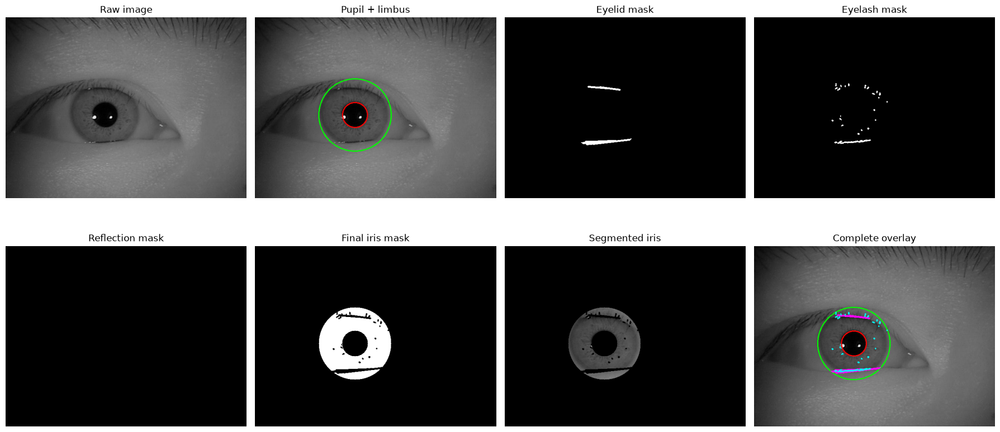

In [13]:
# ============================================================
# 14. Visualize the single-image segmentation
# ============================================================

def overlay_boundaries(
    gray,
    pupil,
    limbus,
    iris_mask=None,
    eyelid_mask=None,
    eyelash_mask=None,
    reflection_mask=None,
):
    """Create an RGB visualization of detected boundaries and masks."""

    vis = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)

    if limbus is not None:
        cv2.circle(
            vis,
            (int(round(limbus["cx"])), int(round(limbus["cy"]))),
            int(round(limbus["radius"])),
            (0, 255, 0),
            2,
        )

    if pupil is not None:
        cv2.circle(
            vis,
            (int(round(pupil["cx"])), int(round(pupil["cy"]))),
            int(round(pupil["radius"])),
            (255, 0, 0),
            2,
        )

    if eyelid_mask is not None:
        vis[eyelid_mask > 0] = (255, 0, 255)

    if eyelash_mask is not None:
        vis[eyelash_mask > 0] = (0, 255, 255)

    if reflection_mask is not None:
        vis[reflection_mask > 0] = (255, 255, 255)

    return vis


fig, axes = plt.subplots(2, 4, figsize=(18, 9))

axes[0, 0].imshow(sample_gray, cmap="gray")
axes[0, 0].set_title("Raw image")

axes[0, 1].imshow(
    overlay_boundaries(
        sample_gray,
        sample_result.get("pupil"),
        sample_result.get("limbus"),
    )
)
axes[0, 1].set_title("Pupil + limbus")

axes[0, 2].imshow(sample_result["eyelid_mask"], cmap="gray")
axes[0, 2].set_title("Eyelid mask")

axes[0, 3].imshow(sample_result["eyelash_mask"], cmap="gray")
axes[0, 3].set_title("Eyelash mask")

axes[1, 0].imshow(sample_result["reflection_mask"], cmap="gray")
axes[1, 0].set_title("Reflection mask")

axes[1, 1].imshow(sample_result["iris_mask"], cmap="gray")
axes[1, 1].set_title("Final iris mask")

axes[1, 2].imshow(sample_result["segmented"], cmap="gray")
axes[1, 2].set_title("Segmented iris")

axes[1, 3].imshow(
    overlay_boundaries(
        sample_gray,
        sample_result.get("pupil"),
        sample_result.get("limbus"),
        eyelid_mask=sample_result["eyelid_mask"],
        eyelash_mask=sample_result["eyelash_mask"],
        reflection_mask=sample_result["reflection_mask"],
    )
)
axes[1, 3].set_title("Complete overlay")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 15. Build output paths

Outputs are kept separate from the raw dataset.

```text
results/
└── iris_segmentation/
    ├── segmented/
    │   ├── CASIA-Iris-Thousand/
    │   └── IITD/
    ├── masks/
    │   ├── iris/
    │   ├── eyelid/
    │   ├── eyelash/
    │   └── reflection/
    ├── previews/
    └── segmentation_metadata.csv
```

The original raw files are never overwritten.

In [14]:
# ============================================================
# 15. Output path helpers
# ============================================================

def dataset_safe_name(dataset):
    return (
        str(dataset)
        .replace("/", "_")
        .replace("\\", "_")
        .replace(" ", "_")
    )


def identity_safe_name(identity):
    if pd.isna(identity):
        return "unknown_identity"
    return str(identity).replace("/", "_").replace("\\", "_")


def eye_safe_name(eye):
    if pd.isna(eye):
        return "UNKNOWN"
    return str(eye).replace("/", "_")


def make_output_paths(row):
    dataset_name = dataset_safe_name(row["dataset"])
    identity_name = identity_safe_name(row["identity"])
    eye_name = eye_safe_name(row["eye"])
    stem = Path(row["filename"]).stem

    base = f"{stem}_segmented.png"

    segmented_path = (
        SEGMENTED_DIR /
        dataset_name /
        identity_name /
        eye_name /
        base
    )

    iris_mask_path = (
        MASKS_DIR /
        "iris" /
        dataset_name /
        identity_name /
        eye_name /
        f"{stem}_iris_mask.png"
    )

    eyelid_mask_path = (
        MASKS_DIR /
        "eyelid" /
        dataset_name /
        identity_name /
        eye_name /
        f"{stem}_eyelid_mask.png"
    )

    eyelash_mask_path = (
        MASKS_DIR /
        "eyelash" /
        dataset_name /
        identity_name /
        eye_name /
        f"{stem}_eyelash_mask.png"
    )

    reflection_mask_path = (
        MASKS_DIR /
        "reflection" /
        dataset_name /
        identity_name /
        eye_name /
        f"{stem}_reflection_mask.png"
    )

    return {
        "segmented_path": segmented_path,
        "iris_mask_path": iris_mask_path,
        "eyelid_mask_path": eyelid_mask_path,
        "eyelash_mask_path": eyelash_mask_path,
        "reflection_mask_path": reflection_mask_path,
    }


def ensure_parent_directories(paths):
    for path in paths.values():
        path.parent.mkdir(parents=True, exist_ok=True)

## 16. Process the datasets

The processor:

- reads each raw image,
- runs segmentation,
- stores the segmented image and all individual masks,
- records detection parameters and coverage statistics,
- records failure reasons instead of stopping the entire run.

The metadata table is the important hand-off artifact for later notebooks.

In [15]:
# ============================================================
# 16. Process all images
# ============================================================

rows_to_process = []

for dataset_name, df in metadata.groupby("dataset", dropna=False):
    df = df.copy()

    if MAX_IMAGES_PER_DATASET is not None:
        df = df.sample(
            n=min(MAX_IMAGES_PER_DATASET, len(df)),
            random_state=RANDOM_SEED,
        )

    rows_to_process.append(df)

processing_metadata = pd.concat(
    rows_to_process,
    ignore_index=True,
)

print("Images selected for segmentation:", len(processing_metadata))
display(processing_metadata["dataset"].value_counts())

Images selected for segmentation: 22180


dataset
CASIA-Iris-Thousand    20000
IITD                    2180
Name: count, dtype: int64

In [16]:
# ============================================================
# 17. Run segmentation and save outputs
# ============================================================

records = []

total = len(processing_metadata)

for idx, row in processing_metadata.iterrows():

    original_path = Path(row["full_path"])

    record = {
        "dataset": row["dataset"],
        "identity": row["identity"],
        "eye": row["eye"],
        "filename": row["filename"],
        "original_path": str(original_path),
        "success": False,
        "reason": None,
        "pupil_cx": np.nan,
        "pupil_cy": np.nan,
        "pupil_radius": np.nan,
        "pupil_method": None,
        "pupil_score": np.nan,
        "limbus_cx": np.nan,
        "limbus_cy": np.nan,
        "limbus_radius": np.nan,
        "limbus_method": None,
        "limbus_score": np.nan,
        "limbus_edge_score": np.nan,
        "radius_ratio": np.nan,
        "iris_area_px": np.nan,
        "usable_iris_area_px": np.nan,
        "usable_fraction": np.nan,
        "eyelid_area_px": np.nan,
        "eyelash_area_px": np.nan,
        "reflection_area_px": np.nan,
        "segmented_path": None,
        "iris_mask_path": None,
        "eyelid_mask_path": None,
        "eyelash_mask_path": None,
        "reflection_mask_path": None,
    }

    try:
        gray = safe_read_gray(original_path)
        result = segment_iris_image(gray)

        output_paths = make_output_paths(row)
        ensure_parent_directories(output_paths)

        # Always save masks when the corresponding result exists.
        cv2.imwrite(
            str(output_paths["iris_mask_path"]),
            result["iris_mask"],
        )
        cv2.imwrite(
            str(output_paths["eyelid_mask_path"]),
            result["eyelid_mask"],
        )
        cv2.imwrite(
            str(output_paths["eyelash_mask_path"]),
            result["eyelash_mask"],
        )
        cv2.imwrite(
            str(output_paths["reflection_mask_path"]),
            result["reflection_mask"],
        )

        if result["success"]:
            cv2.imwrite(
                str(output_paths["segmented_path"]),
                result["segmented"],
            )

        pupil = result.get("pupil")
        limbus = result.get("limbus")

        record.update({
            "success": bool(result["success"]),
            "reason": result["reason"],
            "pupil_cx": pupil["cx"] if pupil else np.nan,
            "pupil_cy": pupil["cy"] if pupil else np.nan,
            "pupil_radius": pupil["radius"] if pupil else np.nan,
            "pupil_method": pupil.get("method") if pupil else None,
            "pupil_score": pupil.get("score") if pupil else np.nan,
            "limbus_cx": limbus["cx"] if limbus else np.nan,
            "limbus_cy": limbus["cy"] if limbus else np.nan,
            "limbus_radius": limbus["radius"] if limbus else np.nan,
            "limbus_method": limbus.get("method") if limbus else None,
            "limbus_score": limbus.get("score") if limbus else np.nan,
            "limbus_edge_score": limbus.get("edge_score") if limbus else np.nan,
            "radius_ratio": limbus.get("radius_ratio") if limbus else np.nan,
            "iris_area_px": int(
                np.count_nonzero(result["iris_outer_mask"])
            ) if "iris_outer_mask" in result else np.nan,
            "usable_iris_area_px": int(
                np.count_nonzero(result["iris_mask"])
            ),
            "usable_fraction": result.get("usable_fraction", np.nan),
            "eyelid_area_px": int(
                np.count_nonzero(result["eyelid_mask"])
            ),
            "eyelash_area_px": int(
                np.count_nonzero(result["eyelash_mask"])
            ),
            "reflection_area_px": int(
                np.count_nonzero(result["reflection_mask"])
            ),
            "segmented_path": (
                str(output_paths["segmented_path"])
                if result["success"] else None
            ),
            "iris_mask_path": str(output_paths["iris_mask_path"]),
            "eyelid_mask_path": str(output_paths["eyelid_mask_path"]),
            "eyelash_mask_path": str(output_paths["eyelash_mask_path"]),
            "reflection_mask_path": str(output_paths["reflection_mask_path"]),
        })

    except Exception as exc:
        record["success"] = False
        record["reason"] = f"exception: {type(exc).__name__}: {exc}"

    records.append(record)

    if (idx + 1) % 100 == 0 or (idx + 1) == total:
        print(
            f"Processed {idx + 1}/{total} "
            f"({100 * (idx + 1) / total:.1f}%)"
        )

segmentation_metadata = pd.DataFrame(records)

print("Segmentation finished.")
display(segmentation_metadata.head())

Processed 100/22180 (0.5%)
Processed 200/22180 (0.9%)
Processed 300/22180 (1.4%)
Processed 400/22180 (1.8%)
Processed 500/22180 (2.3%)
Processed 600/22180 (2.7%)
Processed 700/22180 (3.2%)
Processed 800/22180 (3.6%)
Processed 900/22180 (4.1%)
Processed 1000/22180 (4.5%)
Processed 1100/22180 (5.0%)
Processed 1200/22180 (5.4%)
Processed 1300/22180 (5.9%)
Processed 1400/22180 (6.3%)
Processed 1500/22180 (6.8%)
Processed 1600/22180 (7.2%)
Processed 1700/22180 (7.7%)
Processed 1800/22180 (8.1%)
Processed 1900/22180 (8.6%)
Processed 2000/22180 (9.0%)
Processed 2100/22180 (9.5%)
Processed 2200/22180 (9.9%)
Processed 2300/22180 (10.4%)
Processed 2400/22180 (10.8%)
Processed 2500/22180 (11.3%)
Processed 2600/22180 (11.7%)
Processed 2700/22180 (12.2%)
Processed 2800/22180 (12.6%)
Processed 2900/22180 (13.1%)
Processed 3000/22180 (13.5%)
Processed 3100/22180 (14.0%)
Processed 3200/22180 (14.4%)
Processed 3300/22180 (14.9%)
Processed 3400/22180 (15.3%)
Processed 3500/22180 (15.8%)
Processed 3600/2

,dataset,identity,eye,filename,original_path,success,reason,pupil_cx,pupil_cy,pupil_radius,...,usable_iris_area_px,usable_fraction,eyelid_area_px,eyelash_area_px,reflection_area_px,segmented_path,iris_mask_path,eyelid_mask_path,eyelash_mask_path,reflection_mask_path
0,CASIA-Iris-Thousand,0,L,S5000L00.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,ok,265.0,259.0,33.0,...,23371,0.808210,1455,909,0,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...
1,CASIA-Iris-Thousand,0,L,S5000L01.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,ok,284.0,250.0,34.0,...,22813,0.788913,1655,1183,0,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...
2,CASIA-Iris-Thousand,0,L,S5000L02.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,ok,555.0,248.0,42.0,...,21951,0.777935,0,379,108,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...
3,CASIA-Iris-Thousand,0,L,S5000L03.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,ok,338.0,153.0,91.0,...,40150,0.575801,776,1120,192,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...
4,CASIA-Iris-Thousand,0,L,S5000L04.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,ok,633.0,423.0,44.0,...,54885,0.892947,1090,1514,392,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...


In [17]:
# ============================================================
# 18. Save segmentation metadata
# ============================================================

SEGMENTATION_METADATA_PATH = RESULTS_DIR / "segmentation_metadata.csv"

segmentation_metadata.to_csv(
    SEGMENTATION_METADATA_PATH,
    index=False,
)

print("Saved:", SEGMENTATION_METADATA_PATH)

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_segmentation\segmentation_metadata.csv


## 19. Segmentation statistics

These statistics are diagnostic.

They do **not** replace Notebook 05 quality assessment.

Important values include:
- total images,
- successful segmentation count,
- pupil detection failure count,
- limbus detection failure count,
- mean usable-iris coverage,
- mean pupil/limbus radius ratio.

In [18]:
# ============================================================
# 19. Segmentation statistics
# ============================================================

total_images = len(segmentation_metadata)
successful = int(segmentation_metadata["success"].sum())

summary = {
    "total_images": total_images,
    "successful_segmentations": successful,
    "failed_segmentations": total_images - successful,
    "success_rate_percent": (
        100 * successful / total_images
        if total_images else 0.0
    ),
    "mean_usable_fraction": (
        segmentation_metadata.loc[
            segmentation_metadata["success"],
            "usable_fraction"
        ].mean()
    ),
    "median_usable_fraction": (
        segmentation_metadata.loc[
            segmentation_metadata["success"],
            "usable_fraction"
        ].median()
    ),
    "mean_pupil_radius": (
        segmentation_metadata["pupil_radius"].mean()
    ),
    "mean_limbus_radius": (
        segmentation_metadata["limbus_radius"].mean()
    ),
    "mean_limbus_pupil_ratio": (
        segmentation_metadata["radius_ratio"].mean()
    ),
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["metric", "value"],
)

display(summary_df)

print("\nFailure reasons:")
display(
    segmentation_metadata.loc[
        ~segmentation_metadata["success"],
        "reason"
    ].value_counts(dropna=False)
)

,metric,value
0,total_images,22180.000000
1,successful_segmentations,22176.000000
2,failed_segmentations,4.000000
3,success_rate_percent,99.981966
4,mean_usable_fraction,0.763239
5,median_usable_fraction,0.783562
6,mean_pupil_radius,37.660850
7,mean_limbus_radius,116.538014
8,mean_limbus_pupil_ratio,3.306239



Failure reasons:


reason
pupil_detection_failed    4
Name: count, dtype: int64

In [19]:
# ============================================================
# 20. Dataset-wise segmentation summary
# ============================================================

dataset_segmentation_summary = (
    segmentation_metadata
    .groupby("dataset")
    .agg(
        total_images=("filename", "count"),
        successful=("success", "sum"),
        mean_usable_fraction=("usable_fraction", "mean"),
        median_usable_fraction=("usable_fraction", "median"),
        mean_pupil_radius=("pupil_radius", "mean"),
        mean_limbus_radius=("limbus_radius", "mean"),
        mean_radius_ratio=("radius_ratio", "mean"),
    )
    .reset_index()
)

dataset_segmentation_summary["success_rate_percent"] = (
    100 *
    dataset_segmentation_summary["successful"] /
    dataset_segmentation_summary["total_images"]
)

display(dataset_segmentation_summary)

dataset_summary_path = RESULTS_DIR / "segmentation_summary_by_dataset.csv"

dataset_segmentation_summary.to_csv(
    dataset_summary_path,
    index=False,
)

print("Saved:", dataset_summary_path)

,dataset,total_images,successful,mean_usable_fraction,median_usable_fraction,mean_pupil_radius,mean_limbus_radius,mean_radius_ratio,success_rate_percent
0,CASIA-Iris-Thousand,20000,20000,0.783944,0.792782,37.425400,118.628850,3.393147,100.000000
1,IITD,2180,2176,0.572936,0.599404,39.824908,97.320772,2.507446,99.816514


Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_segmentation\segmentation_summary_by_dataset.csv


## 21. Visual quality-control previews

A segmentation notebook should not be judged from CSV statistics alone.

The following previews display:

1. raw image,
2. detected pupil and limbus,
3. eyelid mask,
4. eyelash mask,
5. reflection mask,
6. final iris mask,
7. final segmented iris.

The previews are saved to `results/iris_segmentation/previews/`.


Dataset: CASIA-Iris-Thousand


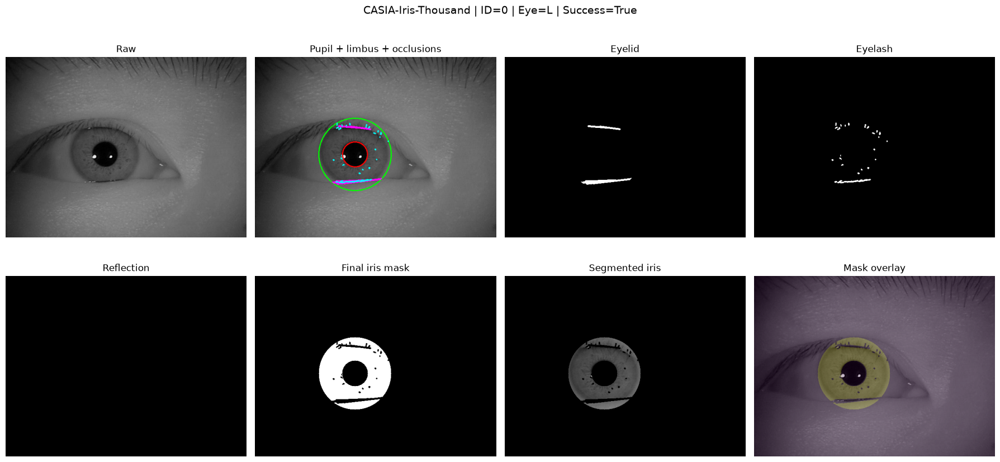

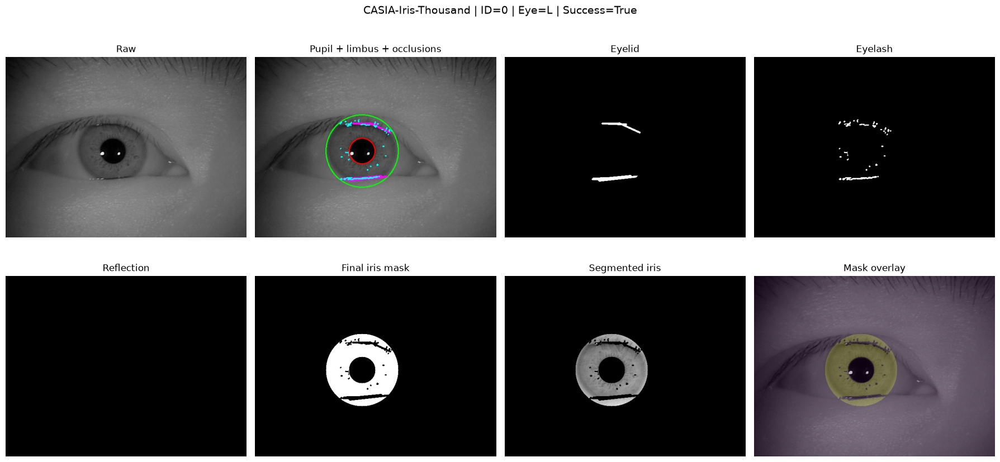

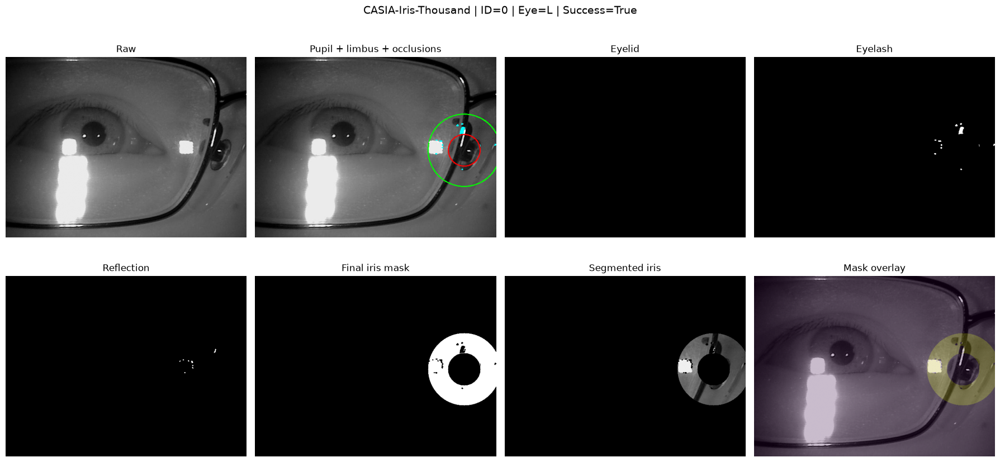

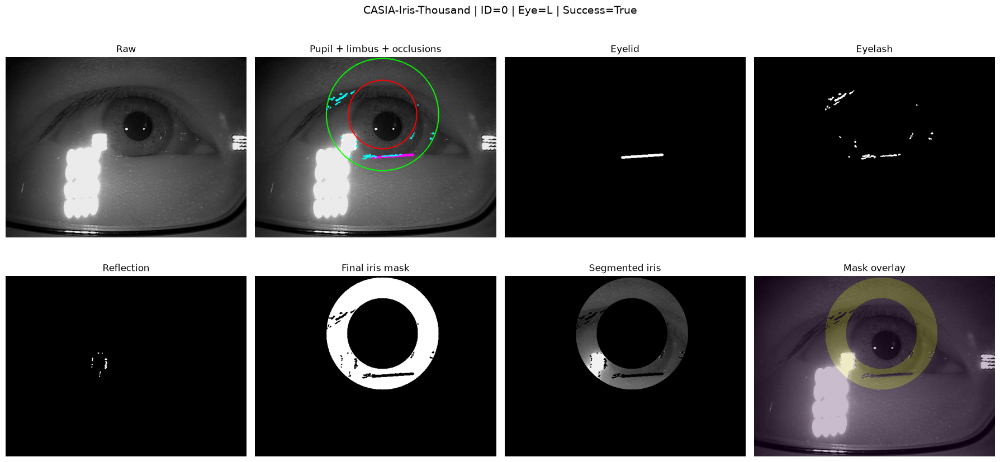

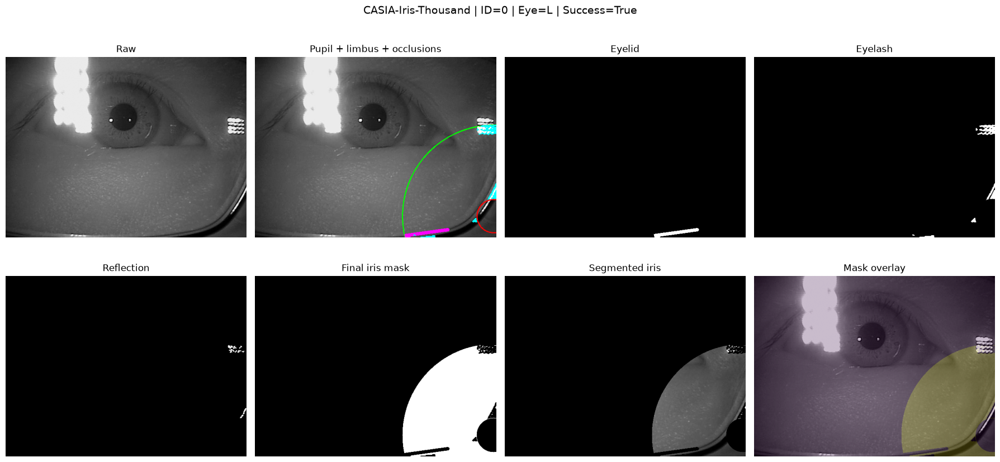

...

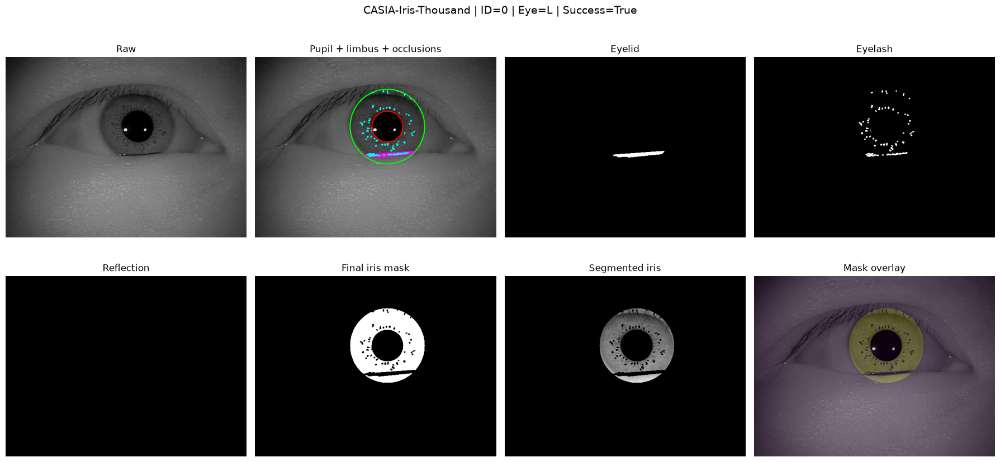

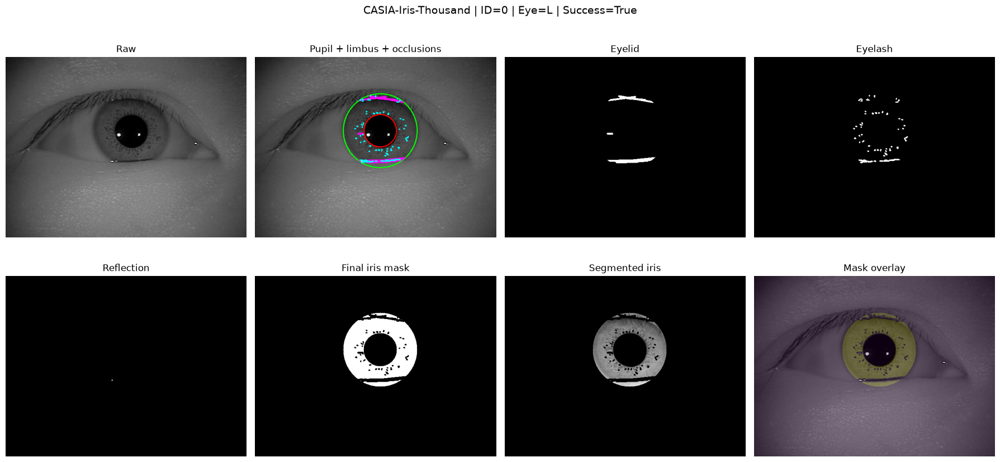

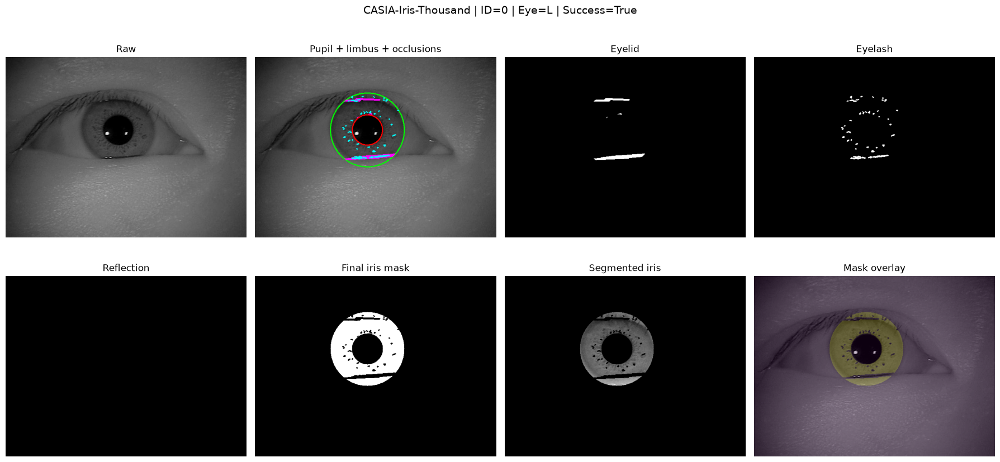

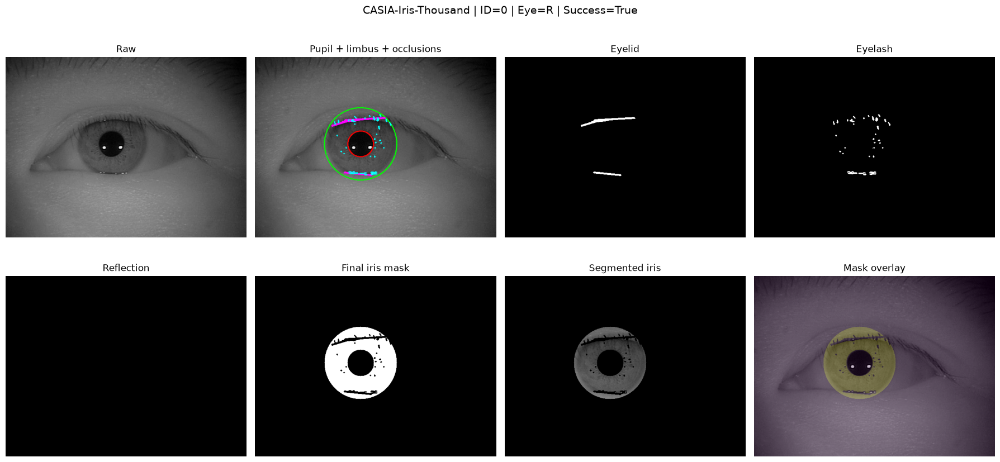

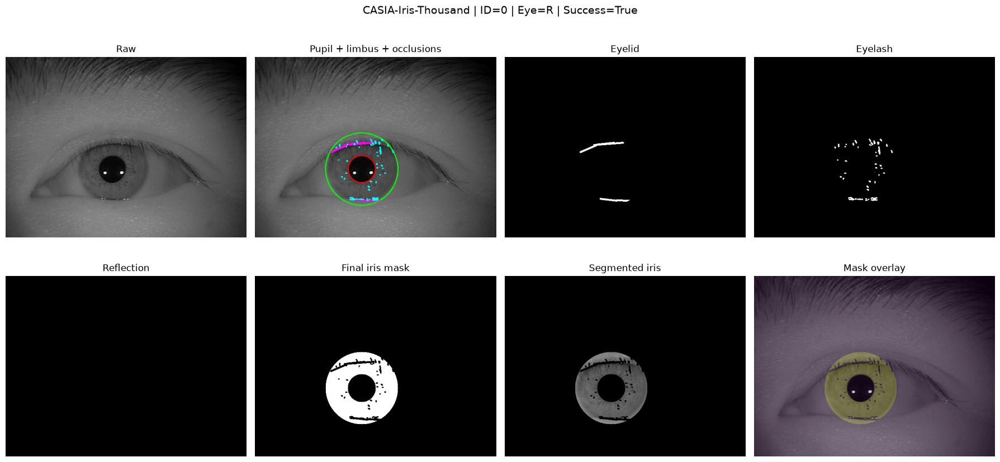


Dataset: IITD


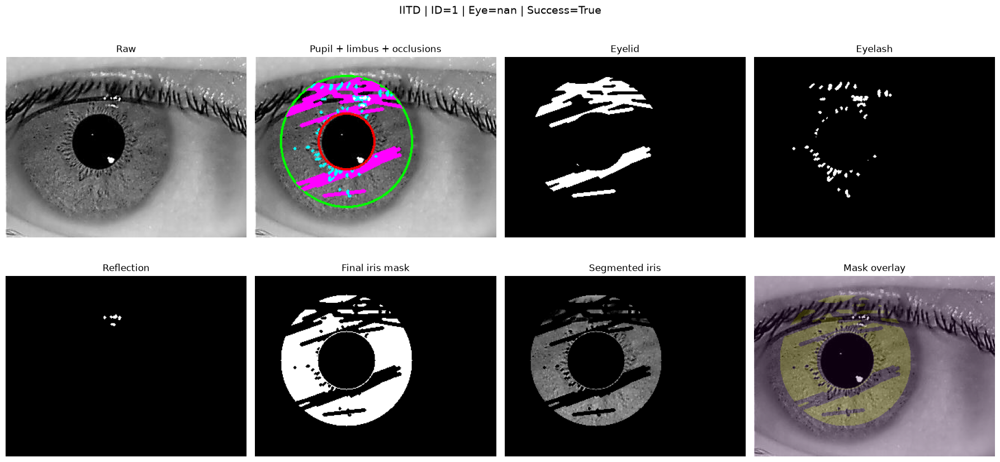

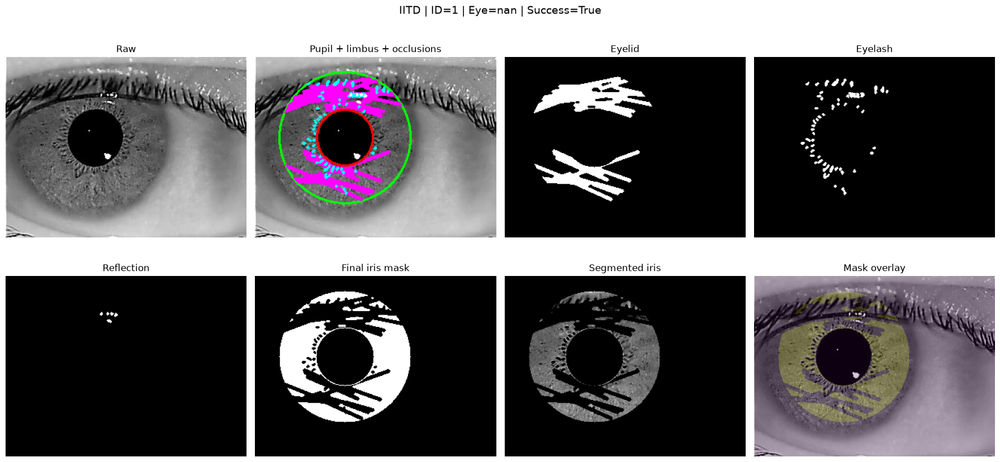

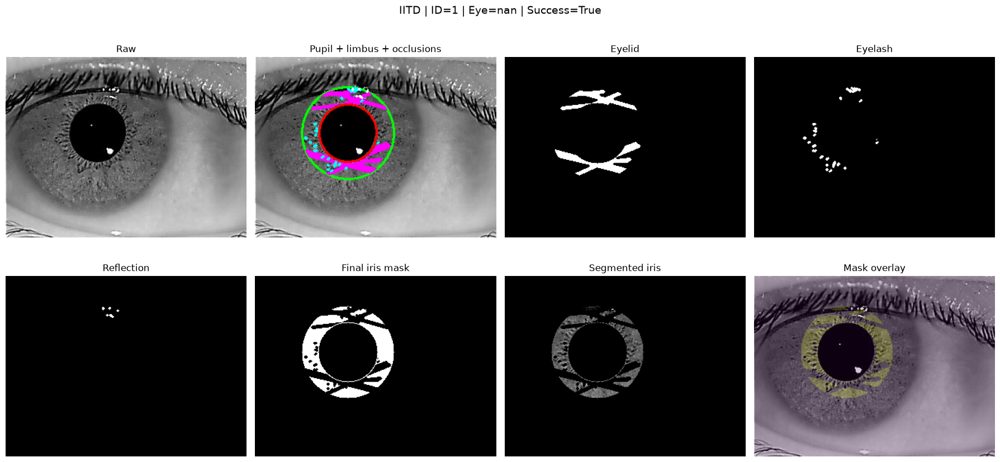

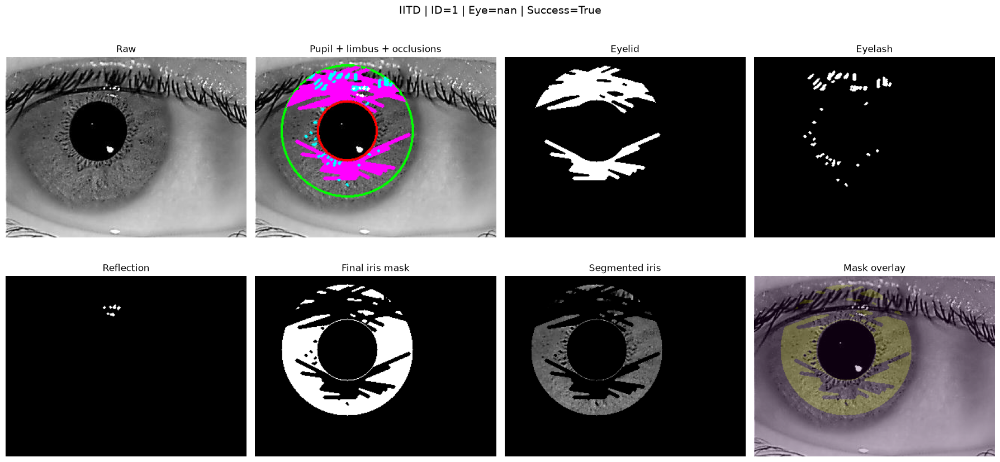

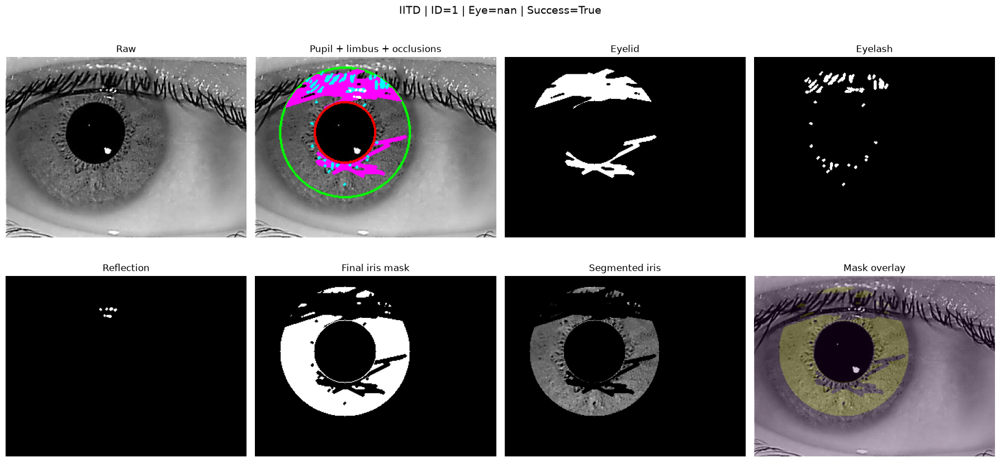

...

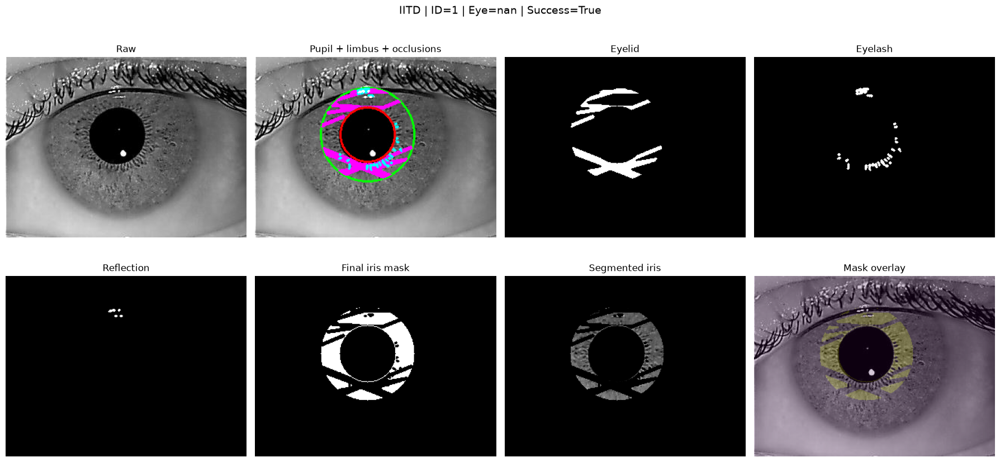

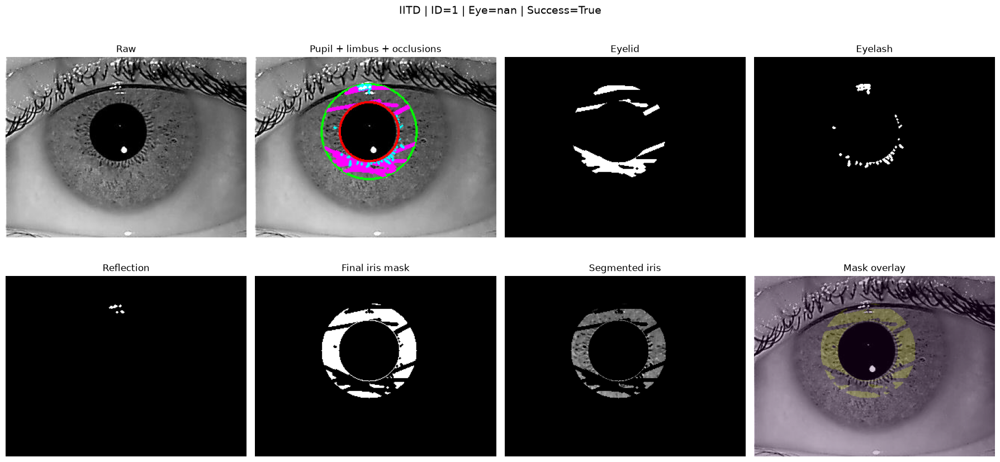

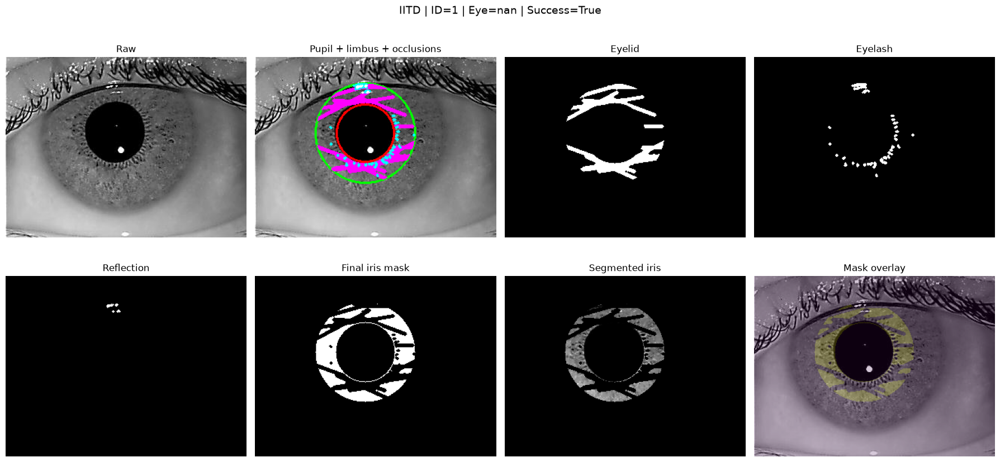

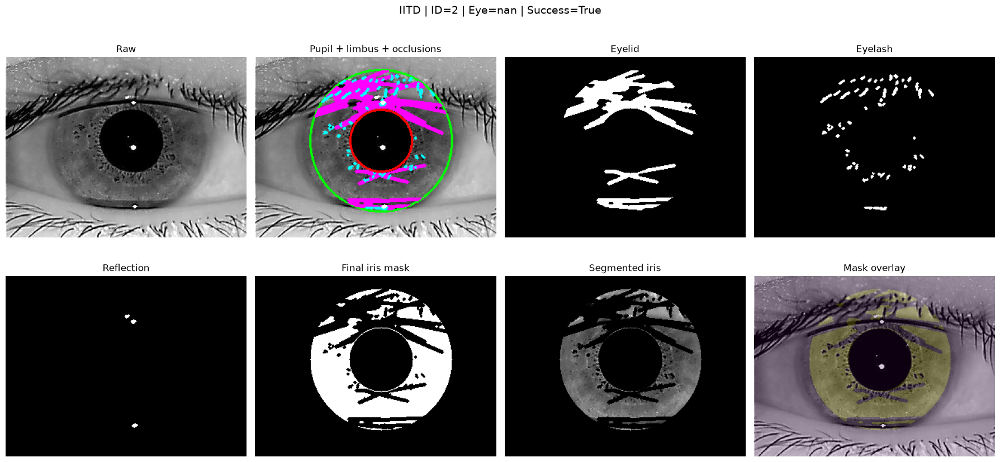

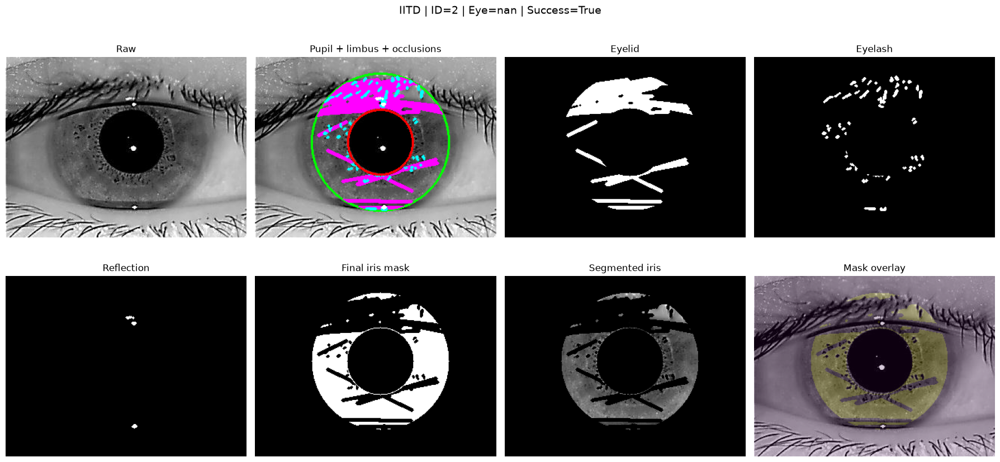

In [20]:
# ============================================================
# 21. Save representative previews
# ============================================================

def create_preview(row):
    original = safe_read_gray(row["original_path"])

    pupil = None
    limbus = None

    if pd.notna(row["pupil_cx"]):
        pupil = {
            "cx": row["pupil_cx"],
            "cy": row["pupil_cy"],
            "radius": row["pupil_radius"],
        }

    if pd.notna(row["limbus_cx"]):
        limbus = {
            "cx": row["limbus_cx"],
            "cy": row["limbus_cy"],
            "radius": row["limbus_radius"],
        }

    iris_mask = cv2.imread(
        str(row["iris_mask_path"]),
        cv2.IMREAD_GRAYSCALE,
    )

    eyelid_mask = cv2.imread(
        str(row["eyelid_mask_path"]),
        cv2.IMREAD_GRAYSCALE,
    )

    eyelash_mask = cv2.imread(
        str(row["eyelash_mask_path"]),
        cv2.IMREAD_GRAYSCALE,
    )

    reflection_mask = cv2.imread(
        str(row["reflection_mask_path"]),
        cv2.IMREAD_GRAYSCALE,
    )

    segmented = None

    if row["success"] and row["segmented_path"]:
        segmented = cv2.imread(
            str(row["segmented_path"]),
            cv2.IMREAD_GRAYSCALE,
        )

    overlay = overlay_boundaries(
        original,
        pupil,
        limbus,
        eyelid_mask=eyelid_mask,
        eyelash_mask=eyelash_mask,
        reflection_mask=reflection_mask,
    )

    if segmented is None:
        segmented = np.zeros_like(original)

    fig, axes = plt.subplots(2, 4, figsize=(18, 9))

    axes[0, 0].imshow(original, cmap="gray")
    axes[0, 0].set_title("Raw")

    axes[0, 1].imshow(overlay)
    axes[0, 1].set_title("Pupil + limbus + occlusions")

    axes[0, 2].imshow(eyelid_mask, cmap="gray")
    axes[0, 2].set_title("Eyelid")

    axes[0, 3].imshow(eyelash_mask, cmap="gray")
    axes[0, 3].set_title("Eyelash")

    axes[1, 0].imshow(reflection_mask, cmap="gray")
    axes[1, 0].set_title("Reflection")

    axes[1, 1].imshow(iris_mask, cmap="gray")
    axes[1, 1].set_title("Final iris mask")

    axes[1, 2].imshow(segmented, cmap="gray")
    axes[1, 2].set_title("Segmented iris")

    axes[1, 3].imshow(original, cmap="gray")
    axes[1, 3].imshow(
        iris_mask > 0,
        alpha=0.20,
    )
    axes[1, 3].set_title("Mask overlay")

    for ax in axes.flat:
        ax.axis("off")

    plt.suptitle(
        f"{row['dataset']} | ID={row['identity']} | Eye={row['eye']} | "
        f"Success={row['success']}",
        fontsize=14,
    )

    plt.tight_layout()

    dataset_name = dataset_safe_name(row["dataset"])
    stem = Path(row["filename"]).stem

    preview_path = PREVIEW_DIR / f"{dataset_name}_{stem}_preview.png"

    plt.savefig(
        preview_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    return preview_path


for dataset_name, df in segmentation_metadata.groupby("dataset"):
    successful_df = df[df["success"]].head(PREVIEW_COUNT_PER_DATASET)

    print("\nDataset:", dataset_name)

    for _, row in successful_df.iterrows():
        create_preview(row)

## 22. Failure review table

Images that fail pupil or limbus detection are retained in the metadata rather than silently discarded.

This is important scientifically: a detector with hidden failures can create downstream selection bias.

In [21]:
# ============================================================
# 22. Failure review
# ============================================================

failure_table = segmentation_metadata[
    ~segmentation_metadata["success"]
].copy()

display(
    failure_table[
        [
            "dataset",
            "identity",
            "eye",
            "filename",
            "reason",
        ]
    ].head(50)
)

FAILURE_REPORT_PATH = RESULTS_DIR / "segmentation_failures.csv"

failure_table.to_csv(
    FAILURE_REPORT_PATH,
    index=False,
)

print("Saved:", FAILURE_REPORT_PATH)

,dataset,identity,eye,filename,reason
21747,IITD,175,NaN,08_R.bmp,pupil_detection_failed
22010,IITD,202,NaN,01_L.bmp,pupil_detection_failed
22011,IITD,202,NaN,02_L.bmp,pupil_detection_failed
22014,IITD,202,NaN,05_L.bmp,pupil_detection_failed


Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_segmentation\segmentation_failures.csv


## 23. Segmentation coverage distribution

The usable-fraction distribution helps identify suspicious segmentation results.

Very low values may indicate:
- a poor boundary estimate,
- excessive eyelid masking,
- excessive eyelash masking,
- excessive reflection masking.

This is diagnostic only. Final image-quality filtering belongs to Notebook 05.

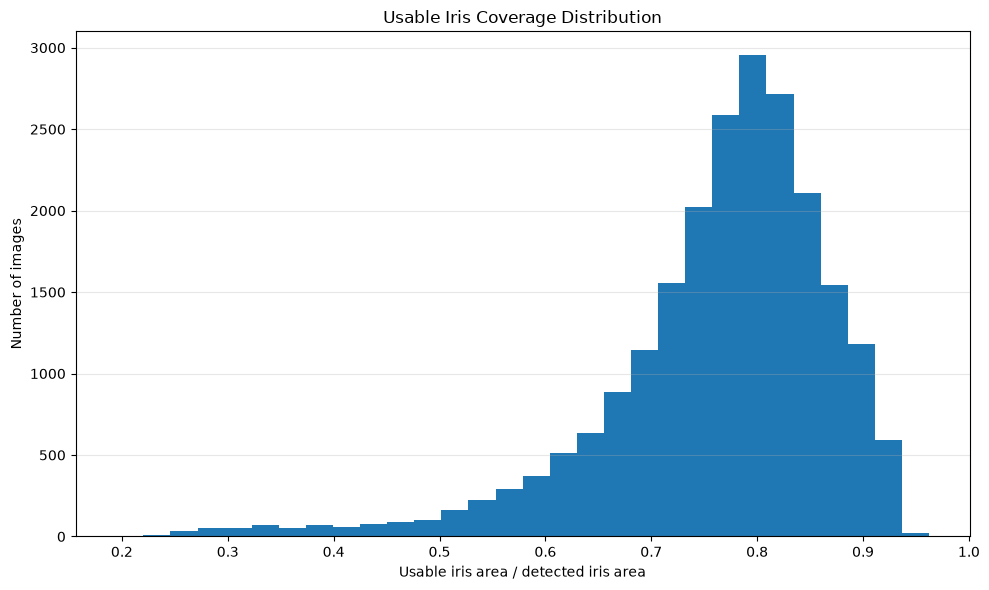

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_segmentation\usable_iris_coverage_distribution.png


In [22]:
# ============================================================
# 23. Plot usable iris coverage
# ============================================================

plt.figure(figsize=(10, 6))

valid_coverage = segmentation_metadata.loc[
    segmentation_metadata["success"],
    "usable_fraction",
].dropna()

if len(valid_coverage):
    plt.hist(
        valid_coverage,
        bins=30,
    )

plt.xlabel("Usable iris area / detected iris area")
plt.ylabel("Number of images")
plt.title("Usable Iris Coverage Distribution")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

coverage_plot_path = RESULTS_DIR / "usable_iris_coverage_distribution.png"

plt.savefig(
    coverage_plot_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", coverage_plot_path)

## 24. Check segmentation output files

Verify that every successful image has:

- segmented iris image,
- final iris mask,
- eyelid mask,
- eyelash mask,
- reflection mask.

In [23]:
# ============================================================
# 24. Output verification
# ============================================================

def path_exists(path_value):
    """Safely check whether a stored file path exists."""

    if pd.isna(path_value):
        return False

    if not isinstance(path_value, (str, Path)):
        return False

    if isinstance(path_value, str) and not path_value.strip():
        return False

    return Path(path_value).exists()


verification_rows = []

for _, row in segmentation_metadata.iterrows():

    checks = {
        "segmented_exists": path_exists(
            row["segmented_path"]
        ),

        "iris_mask_exists": path_exists(
            row["iris_mask_path"]
        ),

        "eyelid_mask_exists": path_exists(
            row["eyelid_mask_path"]
        ),

        "eyelash_mask_exists": path_exists(
            row["eyelash_mask_path"]
        ),

        "reflection_mask_exists": path_exists(
            row["reflection_mask_path"]
        ),
    }

    verification_rows.append(checks)


verification_df = pd.DataFrame(verification_rows)

display(
    verification_df.mean()
    .rename("completion_rate")
    .to_frame()
)

,completion_rate
segmented_exists,0.99982
iris_mask_exists,1.00000
eyelid_mask_exists,1.00000
eyelash_mask_exists,1.00000
reflection_mask_exists,1.00000


## 25. Final outputs

At the end of Notebook 02, the project should contain:

```text
results/iris_segmentation/
├── segmented/
├── masks/
│   ├── iris/
│   ├── eyelid/
│   ├── eyelash/
│   └── reflection/
├── previews/
├── segmentation_metadata.csv
├── segmentation_summary_by_dataset.csv
├── segmentation_failures.csv
└── usable_iris_coverage_distribution.png
```

### Main hand-off file

`segmentation_metadata.csv` is the critical output for later notebooks.

It tells later stages exactly which raw image produced which segmented image and which masks were used.

In [24]:
# ============================================================
# 25. Final output verification
# ============================================================

print("Notebook 02 output directory:")
print(RESULTS_DIR)

print("\nTop-level generated files:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print("\nSegmentation success rate:")
print(
    f"{segmentation_metadata['success'].mean() * 100:.2f}%"
    if len(segmentation_metadata)
    else "N/A"
)

print("\nNotebook 02 completed.")

Notebook 02 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_segmentation

Top-level generated files:
- segmentation_failures.csv
- segmentation_metadata.csv
- segmentation_summary_by_dataset.csv
- usable_iris_coverage_distribution.png

Segmentation success rate:
99.98%

Notebook 02 completed.


## 26. What this notebook hands to Notebook 03

Notebook 03 performs iris normalization using the Rubber Sheet Model.

The expected hand-off is:

```text
Notebook 01
Raw image + metadata
        |
        v
Notebook 02
Segmented iris + masks + boundaries
        |
        v
Notebook 03
Rubber-sheet normalization
        |
        v
Fixed-size normalized iris texture
```

Notebook 02 must therefore remain independent of normalization.

### Important research rule

Do not train or fine-tune a segmentation neural network in this notebook unless a valid pixel-level segmentation-label dataset is available. The current implementation is deliberately label-free and reproducible.